In [22]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_style('darkgrid')


In [23]:
df = pd.read_csv(r"C:\Users\volga\Desktop\taxi_forecasting\taxi_weather_clean_daily.csv", parse_dates=["date"])
df = df.sort_values("date")
df

,day,month,year,date,day_of_week,day_of_year,pickup_count,sndp,temp,wdsp,prcp
0,1,1,2016,2016-01-01 00:00:00+00:00,6,1,345036,0.0,40.4,6.5,0.03
1,2,1,2016,2016-01-02 00:00:00+00:00,7,2,312830,0.0,35.8,6.0,0.00
2,3,1,2016,2016-01-03 00:00:00+00:00,1,3,302878,0.0,38.4,6.4,0.00
3,4,1,2016,2016-01-04 00:00:00+00:00,2,4,316008,0.0,30.8,7.0,0.00
4,5,1,2016,2016-01-05 00:00:00+00:00,3,5,343128,0.0,18.4,6.2,0.00
...,...,...,...,...,...,...,...,...,...,...,...
1456,27,12,2019,2019-12-27 00:00:00+00:00,6,361,169618,0.0,49.4,4.7,0.00
1457,28,12,2019,2019-12-28 00:00:00+00:00,7,362,172030,0.0,48.0,3.8,0.00
1458,29,12,2019,2019-12-29 00:00:00+00:00,1,363,165128,0.0,42.6,3.1,0.00
1459,30,12,2019,2019-12-30 00:00:00+00:00,2,364,174564,0.0,39.4,10.0,0.56


## Feature Distributions

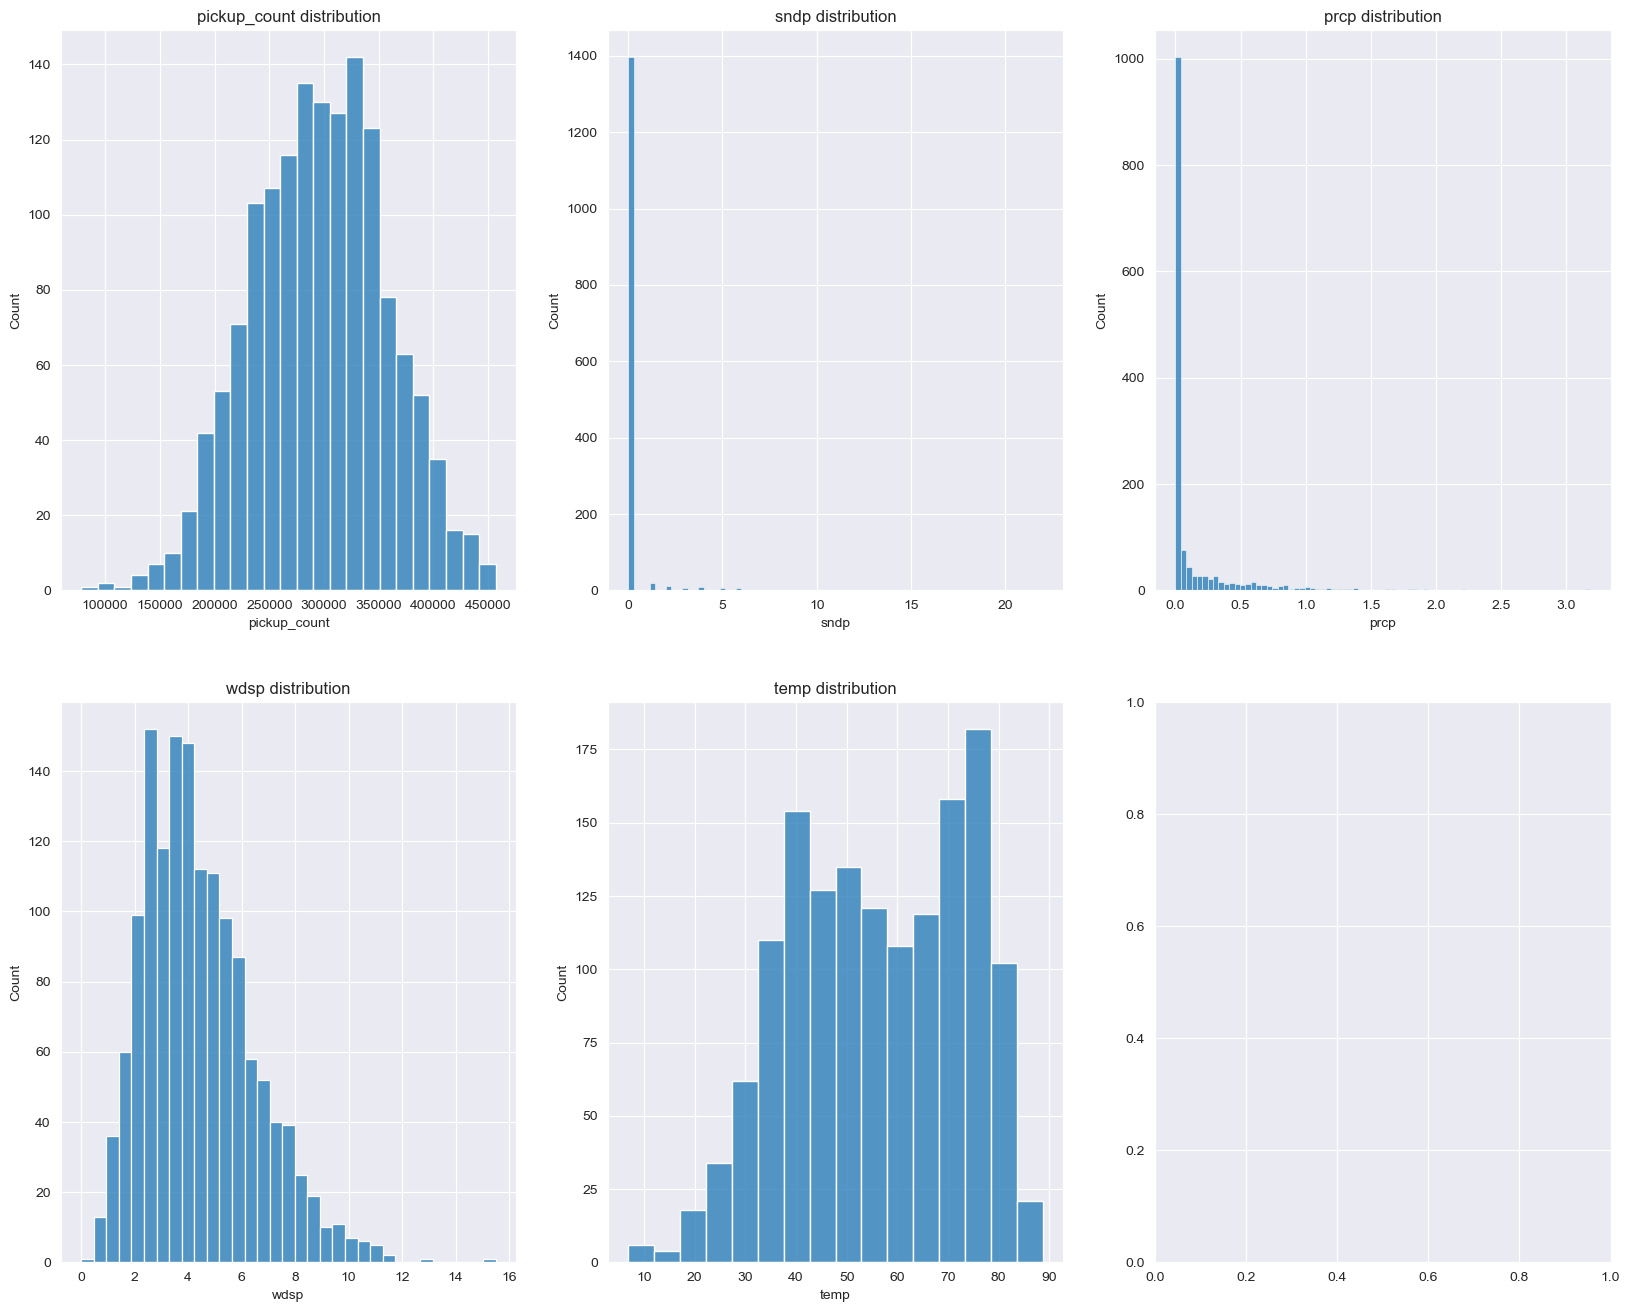

In [24]:
f, axes = plt.subplots(2, 3, figsize=(20, 16))
features = ["pickup_count", "sndp", "prcp", "wdsp", "temp"]
for i, feature in enumerate(features):
    if feature not in excluded_features:
        if set(df[feature].unique()) == {0,1}:
            sns.histplot(df[feature], discrete=True, ax=axes[i//3, i%3])
            axes[i//3, i%3].set_title("{} distribution".format(feature))
        else:
            sns.histplot(df[feature], ax=axes[i//3, i%3])
            axes[i//3, i%3].set_title("{} distribution".format(feature))


## Recurring Temporal Patterns

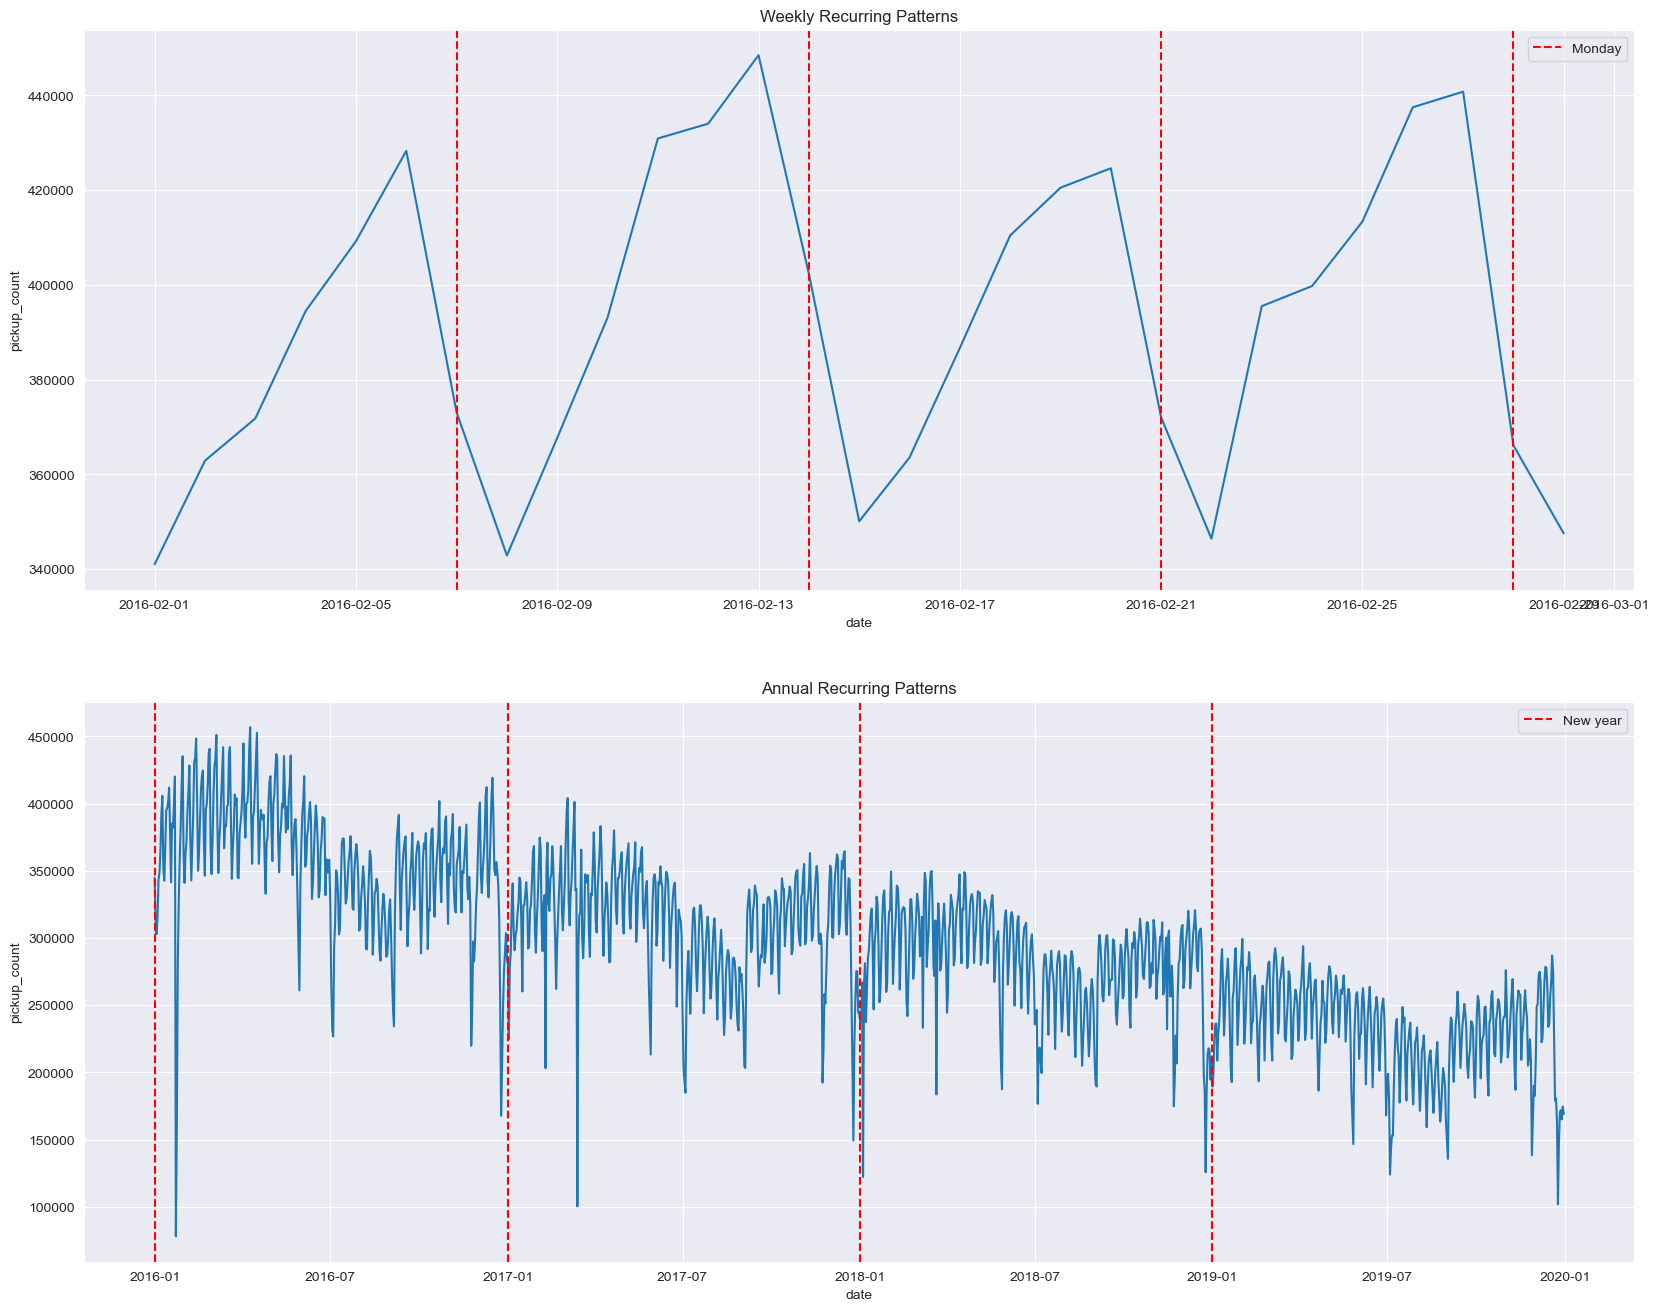

In [25]:
f,axs = plt.subplots(2,1, figsize=(20,16))
df_2016_02 = df[(df["year"]==2016) & (df["month"]==2)]

sns.lineplot(data = df[(df["year"]==2016) & (df["month"]==2)], x = "date", y = "pickup_count", ax = axs[0])
for i, date in enumerate(df_2016_02.loc[(df_2016_02["day_of_week"] == 1) , "date"]):
    axs[0].axvline(
        x=date,
        color="red",
        linestyle="--",
        label="Monday" if i==0 else None
    )
axs[0].legend()
axs[0].set_title("Weekly Recurring Patterns")
axs[0].set_xlabel("date")

sns.lineplot(data = df, x = "date", y = "pickup_count", ax = axs[1])
for i, date in enumerate(df.loc[(df["day"] == 1) & (df["month"]==1) , "date"]):
    axs[1].axvline(
        x=date,
        color="red",
        linestyle="--",
        label="New year" if i==0 else None
    )
axs[1].legend()
axs[1].set_title("Annual Recurring Patterns")
axs[1].set_xlabel("date")

plt.show()


These 2 graphs show multiple seasonal recurring patterns:
- The first graph reveals a weekly pattern where pickup counts start low every Monday and then gradually increase throughout the week, reaching their highest levels over the weekend.
- The second graph reveals a recurring annual pattern, with similar variations in taxi demand occurring at approximately the same periods each year. The graph suggests the presence of yearly seasonality, although the underlying causes cannot be determined from this analysis alone. Possible explanations could include seasonal changes in tourism or other annual events.

The graphs also show a clear downward trend in overall taxi demand from one year to the next, which is further confirmed by the following graph.

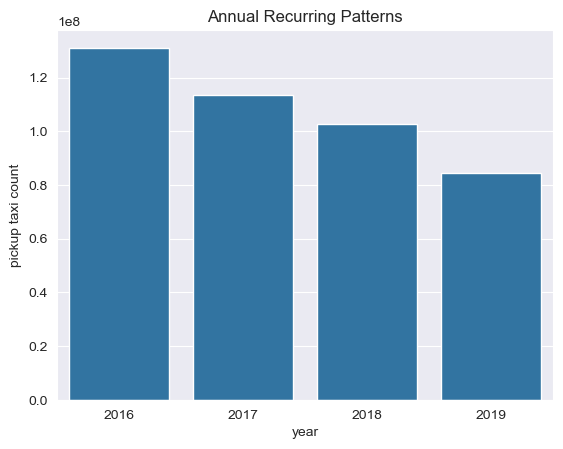

In [46]:
df_yearly = df.groupby("year", as_index=False)["pickup_count"].agg(["sum", "std"])

sns.barplot(data = df_yearly, x = "year", y = "sum")

plt.title("Annual Recurring Patterns")
plt.xlabel("year")
plt.ylabel("pickup taxi count")
plt.show()

## Weather Conditions and Taxi Demand

The following analysis is performed using a single year and a single day of the week. This approach aims to reduce the influence of yearly and weekly seasonality while retaining a sufficient number of observations for the analysis.

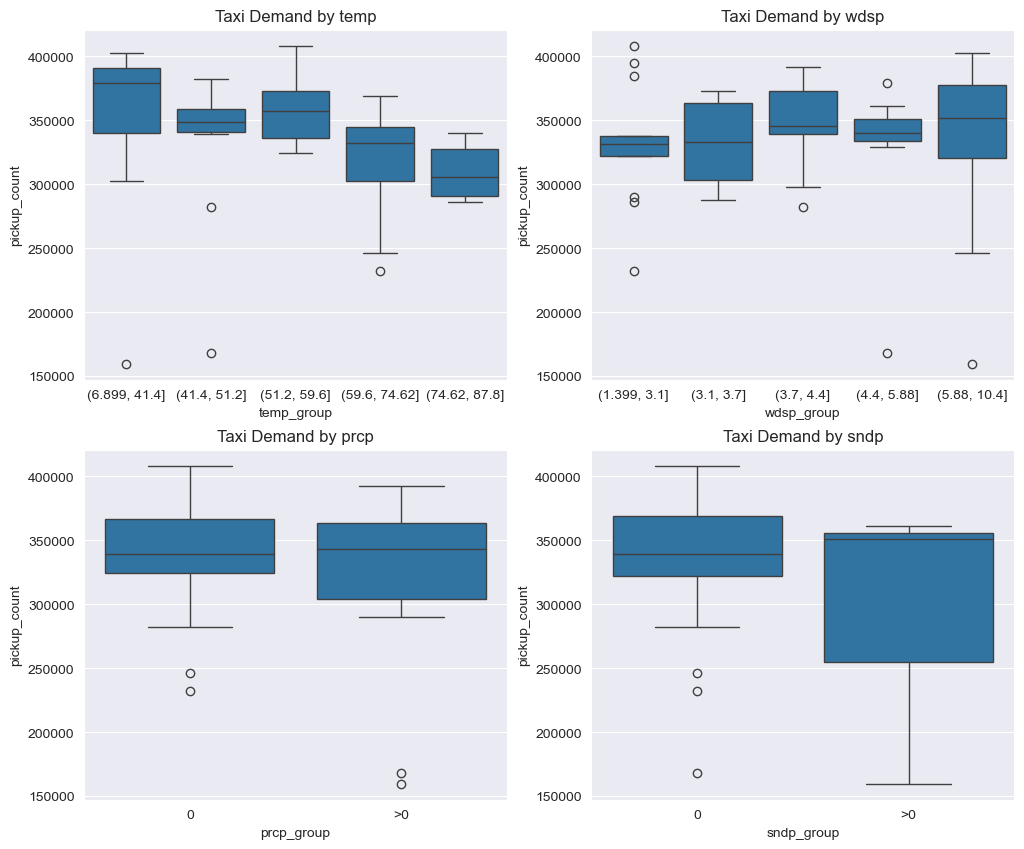

In [27]:
    weather_features_qcut = ["temp", "wdsp"] 
    weather_features_presence = ["prcp", "sndp"]
    
    year = 2016
    day_of_week = 1
    f,axs = plt.subplots(2, 2, figsize=(12,10))
    
    for i, feature in enumerate(weather_features_qcut):
        df_tmp = df[(df["year"] == year) & (df["day_of_week"] == day_of_week)].copy()
        
        df_tmp[f"{feature}_group"] = pd.qcut(
            df_tmp[feature],
            q=5
        )
        
        sns.boxplot(
            data=df_tmp,
            x=f"{feature}_group",
            y="pickup_count",
            ax = axs[0, i]
        )
    
        axs[0, i].set_title(f"Taxi Demand by {feature}")
    
    for i, feature in enumerate(weather_features_presence):
        df_tmp = df[(df["year"] == year) & (df["day_of_week"] == day_of_week)].copy()
    
        df_tmp[f"{feature}_group"] = df_tmp[feature].map(lambda x:"0" if x==0 else ">0")
    
        sns.boxplot(data=df_tmp,
                    x=f"{feature}_group",
                    y="pickup_count",
                    ax = axs[1, i]
        )
    
        axs[1, i].set_title(f"Taxi Demand by {feature}")
    
        

- Overall, the boxplots suggest that taxi demand may decrease as temperature increases, while it may increase with wind speed. This pattern is more pronounced for temperature, for which a clearer downward trend in taxi demand can be observed across the temperature groups.
-  In contrast, the precipitation and snow depth plots do not reveal any significant or consistent pattern in taxi demand.

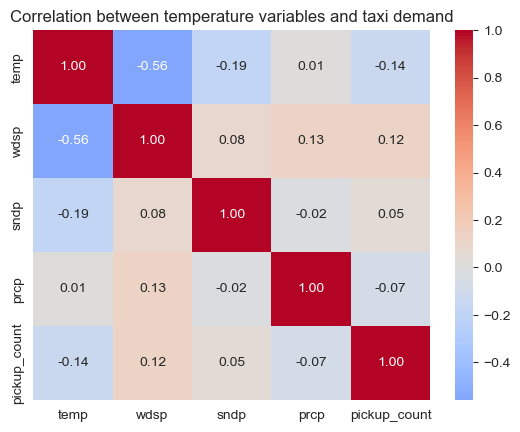

In [31]:
weather_temp = df[["temp",  "wdsp", "sndp", "prcp", "pickup_count"]]

sns.heatmap(
    weather_temp.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation between temperature variables and taxi demand")
plt.show()

- Only mean temperature and mean wind speed show a correlation with taxi demand, and both correlations are very weak, at -0.14 and 0.12, respectively.
- At this stage, we cannot conclude whether including these features would improve the model's performance.
- Further analysis will be needed to better understand the impact of weather conditions on taxi demand and determine whether weather features provide useful predictive information.